# Notebook 03: Gradient Descent with Logistic Regression & GLMs

In this notebook, we extend Gradient Descent from continuous outputs to binary and multiclass
classification through the lens of Generalized Linear Models (GLMs):

1. **Classification Failure of Least Squares:** How distant positive samples corrupt linear regression thresholds.
2. **Sigmoid + MSE Non-Convexity vs. Convex BCE:** Proving why mean squared error creates flat plateaus while Binary Cross-Entropy forms a strictly convex bowl (`06_logistic_mse_vs_bce_convexity.png`).
3. **Linear & Non-Linear Decision Boundaries:** Visualizing the orthogonal normal vector $\mathbf{w}$, concentric ring boundaries via degree-2 polynomials, and moon manifolds via degree-5 polynomials (`07_logistic_gd_decision_boundaries.png`).
4. **Multiclass Softmax & Log-Sum-Exp Stability:** Preventing IEEE-754 overflow for extreme logits.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

REPO_DIR = Path.cwd()
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from src.gd_engine import (
    LogisticRegressionGD,
    PolynomialFeaturesScratch,
    SoftmaxRegressionGD,
    StandardScalerScratch,
    sigmoid_stable,
    softmax_naive,
    softmax_stable,
)
from src.plot_theme import (
    AMBER,
    BG_CANVAS,
    CMAP_SURFACE,
    CORAL,
    CYAN,
    EMERALD,
    PURPLE,
    SLATE_BLUE,
    TEXT_MUTED,
    apply_github_dark_style,
    plot_decision_boundary,
    save_fig,
)

apply_github_dark_style()
np.set_printoptions(precision=4, suppress=True)

## 1. Non-Convex Sigmoid + MSE vs. Strictly Convex BCE (`06_logistic_mse_vs_bce_convexity.png`)

When we combine the Sigmoid link $\hat{y} = \sigma(z)$ with Mean Squared Error $J = \frac{1}{2m}\sum (\hat{y}^{(i)} - y^{(i)})^2$,
the chain rule yields:

$$\frac{\partial J}{\partial w_j} = \frac{1}{m}\sum_{i=1}^m (\hat{y}^{(i)} - y^{(i)}) \cdot \sigma'(z^{(i)}) \cdot x_j^{(i)}$$

When the model is confidently wrong (e.g., $y=1$ but $z \ll 0 \implies \hat{y} \approx 0$), the error is large
($|\hat{y} - y| \approx 1$), but the derivative $\sigma'(z) \approx 0$ vanishes! The gradient $\nabla J \approx 0$,
trapping Gradient Descent on a flat saddle plateau.

Under Binary Cross-Entropy $J_{\text{BCE}} = -\frac{1}{m}\sum [y \ln \hat{y} + (1-y)\ln(1-\hat{y})]$, the $\sigma'(z)$
term in the numerator cancels with $\hat{y}(1-\hat{y})$ in the denominator, yielding the linear error gradient:

$$\frac{\partial J_{\text{BCE}}}{\partial w_j} = \frac{1}{m}\sum_{i=1}^m (\hat{y}^{(i)} - y^{(i)}) x_j^{(i)}$$

which remains steep and drives parameters rapidly toward the global minimum!

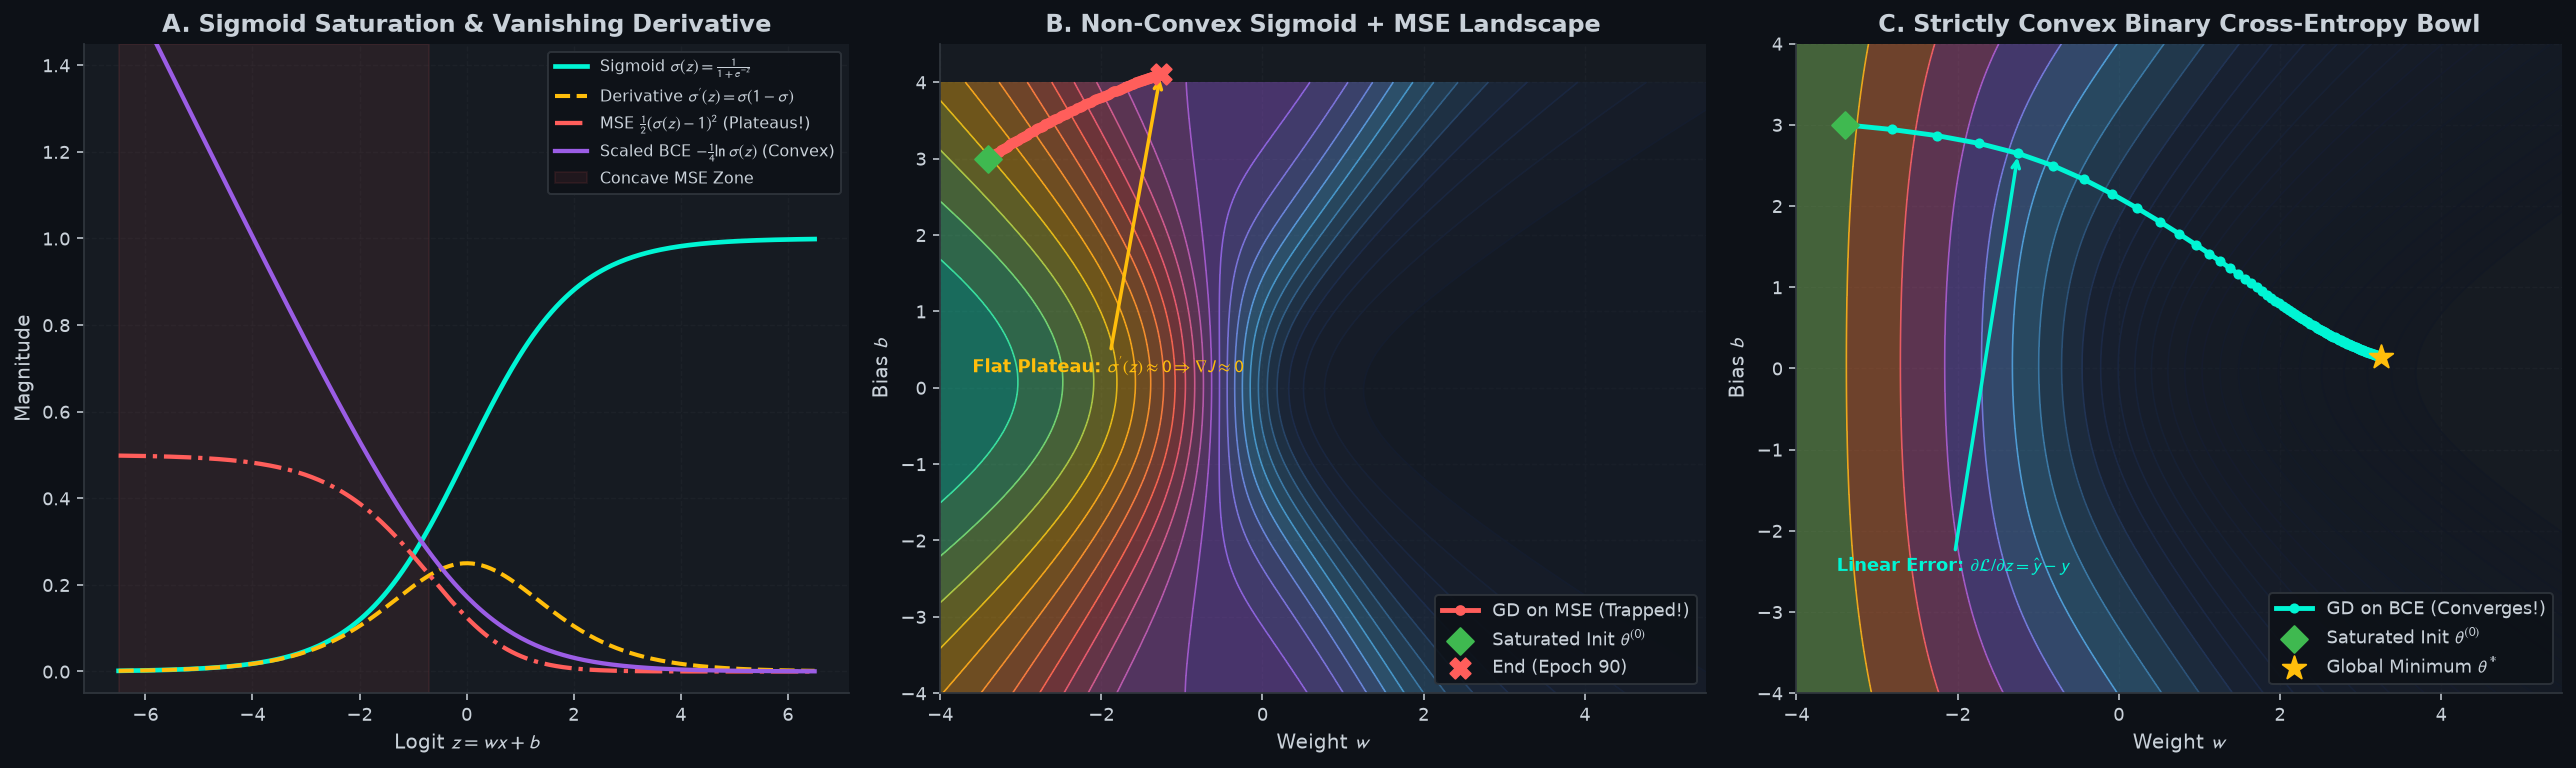

In [2]:
# Generate a 1D binary dataset centered at zero
X_clean = np.array([[-2.2], [-1.8], [-1.3], [-0.9], [-0.6], [0.6], [1.0], [1.4], [1.9], [2.3]])
y_clean = np.array([0, 0, 0, 0, 0, 1, 1, 1, 1, 1], dtype=np.float64)

w_vals = np.linspace(-4.0, 5.5, 110)
b_vals = np.linspace(-4.0, 4.0, 110)
W_g, B_g = np.meshgrid(w_vals, b_vals)
J_mse_grid = np.zeros_like(W_g)
J_bce_grid = np.zeros_like(W_g)

for i in range(W_g.shape[0]):
    for j in range(W_g.shape[1]):
        z_ij = X_clean * W_g[i, j] + B_g[i, j]
        p_ij = sigmoid_stable(z_ij)
        J_mse_grid[i, j] = 0.5 * np.mean((p_ij - y_clean.reshape(-1, 1)) ** 2)
        J_bce_grid[i, j] = np.mean(np.logaddexp(0.0, z_ij) - y_clean.reshape(-1, 1) * z_ij)

# Run Gradient Descent from a saturated, wrong-sign initialization
w_start = np.array([[-3.4]])
b_start = 3.0
epochs_comp = 90

mse_clf = LogisticRegressionGD(learning_rate=0.45, epochs=epochs_comp, loss="mse", penalty="l2", reg_lambda=0.02).fit(
    X_clean, y_clean, W_init=w_start, b_init=b_start
)
bce_clf = LogisticRegressionGD(learning_rate=0.45, epochs=epochs_comp, loss="bce", penalty="l2", reg_lambda=0.02).fit(
    X_clean, y_clean, W_init=w_start, b_init=b_start
)

tr_mse = np.array([[th[0], th[1]] for th in mse_clf.weight_trajectory])
tr_bce = np.array([[th[0], th[1]] for th in bce_clf.weight_trajectory])

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18.5, 5.6))

# Panel 1: 1D Activation & Loss Comparison
z_axis = np.linspace(-6.5, 6.5, 300)
sig_z = sigmoid_stable(z_axis)
dsig_z = sig_z * (1.0 - sig_z)
loss_mse_1d = 0.5 * ((sig_z - 1.0) ** 2)
loss_bce_1d = np.logaddexp(0.0, -z_axis)

ax1.plot(z_axis, sig_z, color=CYAN, linewidth=2.4, label=r"Sigmoid $\sigma(z) = \frac{1}{1+e^{-z}}$")
ax1.plot(z_axis, dsig_z, color=AMBER, linewidth=2.1, linestyle="--", label=r"Derivative $\sigma'(z) = \sigma(1-\sigma)$")
ax1.plot(z_axis, loss_mse_1d, color=CORAL, linewidth=2.2, linestyle="-.", label=r"MSE $\frac{1}{2}(\sigma(z)-1)^2$ (Plateaus!)")
ax1.plot(z_axis, np.clip(loss_bce_1d / 4.0, 0, 1.6), color=PURPLE, linewidth=2.2, label=r"Scaled BCE $-\frac{1}{4}\ln\sigma(z)$ (Convex)")
ax1.axvspan(-6.5, -np.log(2.0), color=CORAL, alpha=0.08, label=r"Concave MSE Zone")
ax1.set_ylim(-0.05, 1.45)
ax1.set_xlabel(r"Logit $z = w x + b$")
ax1.set_ylabel("Magnitude")
ax1.set_title("A. Sigmoid Saturation & Vanishing Derivative")
ax1.legend(loc="upper right", fontsize=8.3)

# Panel 2: MSE Non-Convex Landscape
lev_mse = np.linspace(float(np.min(J_mse_grid)), float(np.max(J_mse_grid)), 26)
ax2.contourf(W_g, B_g, J_mse_grid, levels=lev_mse, cmap=CMAP_SURFACE, alpha=0.38)
ax2.contour(W_g, B_g, J_mse_grid, levels=lev_mse, cmap=CMAP_SURFACE, linewidths=0.85, alpha=0.85)
ax2.plot(tr_mse[:, 0], tr_mse[:, 1], color=CORAL, linewidth=2.5, marker="o", markersize=4.5, label="GD on MSE (Trapped!)")
ax2.scatter(tr_mse[0, 0], tr_mse[0, 1], color=EMERALD, s=95, marker="D", zorder=6, label=r"Saturated Init $\theta^{(0)}$")
ax2.scatter(tr_mse[-1, 0], tr_mse[-1, 1], color=CORAL, s=110, marker="X", zorder=7, label=f"End (Epoch {epochs_comp})")
ax2.annotate(
    r"Flat Plateau: $\sigma'(z) \approx 0 \Rightarrow \nabla J \approx 0$",
    xy=(tr_mse[-1, 0], tr_mse[-1, 1]),
    xytext=(-3.6, 0.2),
    arrowprops=dict(arrowstyle="->", color=AMBER, lw=1.8),
    color=AMBER,
    fontweight="bold",
    fontsize=9.2,
)
ax2.set_xlabel("Weight $w$")
ax2.set_ylabel("Bias $b$")
ax2.set_title("B. Non-Convex Sigmoid + MSE Landscape")
ax2.legend(loc="lower right")

# Panel 3: BCE Convex Landscape
lev_bce = np.geomspace(float(np.min(J_bce_grid)) + 0.02, float(np.max(J_bce_grid)), 26)
ax3.contourf(W_g, B_g, J_bce_grid, levels=lev_bce, cmap=CMAP_SURFACE, alpha=0.38)
ax3.contour(W_g, B_g, J_bce_grid, levels=lev_bce, cmap=CMAP_SURFACE, linewidths=0.85, alpha=0.85)
ax3.plot(tr_bce[:, 0], tr_bce[:, 1], color=CYAN, linewidth=2.5, marker="o", markersize=4.2, label="GD on BCE (Converges!)")
ax3.scatter(tr_bce[0, 0], tr_bce[0, 1], color=EMERALD, s=95, marker="D", zorder=6, label=r"Saturated Init $\theta^{(0)}$")
ax3.scatter(tr_bce[-1, 0], tr_bce[-1, 1], color=AMBER, s=160, marker="*", zorder=7, label=r"Global Minimum $\theta^*$")
ax3.annotate(
    r"Linear Error: $\partial \mathcal{L}/\partial z = \hat{y} - y$",
    xy=(tr_bce[4, 0], tr_bce[4, 1]),
    xytext=(-3.5, -2.5),
    arrowprops=dict(arrowstyle="->", color=CYAN, lw=1.8),
    color=CYAN,
    fontweight="bold",
    fontsize=9.2,
)
ax3.set_xlabel("Weight $w$")
ax3.set_ylabel("Bias $b$")
ax3.set_title("C. Strictly Convex Binary Cross-Entropy Bowl")
ax3.legend(loc="lower right")

fig.tight_layout()
save_fig(fig, REPO_DIR / "assets" / "06_logistic_mse_vs_bce_convexity.png")
plt.show()

## 2. Linear & Non-Linear Decision Boundaries via GD (`07_logistic_gd_decision_boundaries.png`)

Logistic regression defines the decision boundary at posterior probability $P(y=1|\mathbf{x}) = 0.5$,
which corresponds to logit $z = \mathbf{w}^\top \mathbf{x} + b = 0$:
- **Linear Boundary:** The weight vector $\mathbf{w}$ is strictly normal (perpendicular) to the separating hyperplane.
- **Concentric Rings:** Applying a degree-2 polynomial expansion $[x_1, x_2, x_1^2, x_1 x_2, x_2^2]$ enables a circular boundary $w_3 x_1^2 + w_5 x_2^2 + b = 0$.
- **Interleaving Moons:** A degree-5 polynomial basis carves an S-shaped separation manifold.
- **Signed Margin Distance:** The posterior probability is a calibrated monotonic function of the orthogonal distance $d(\mathbf{x}) = (\mathbf{w}^\top \mathbf{x} + b) / \|\mathbf{w}\|_2$.

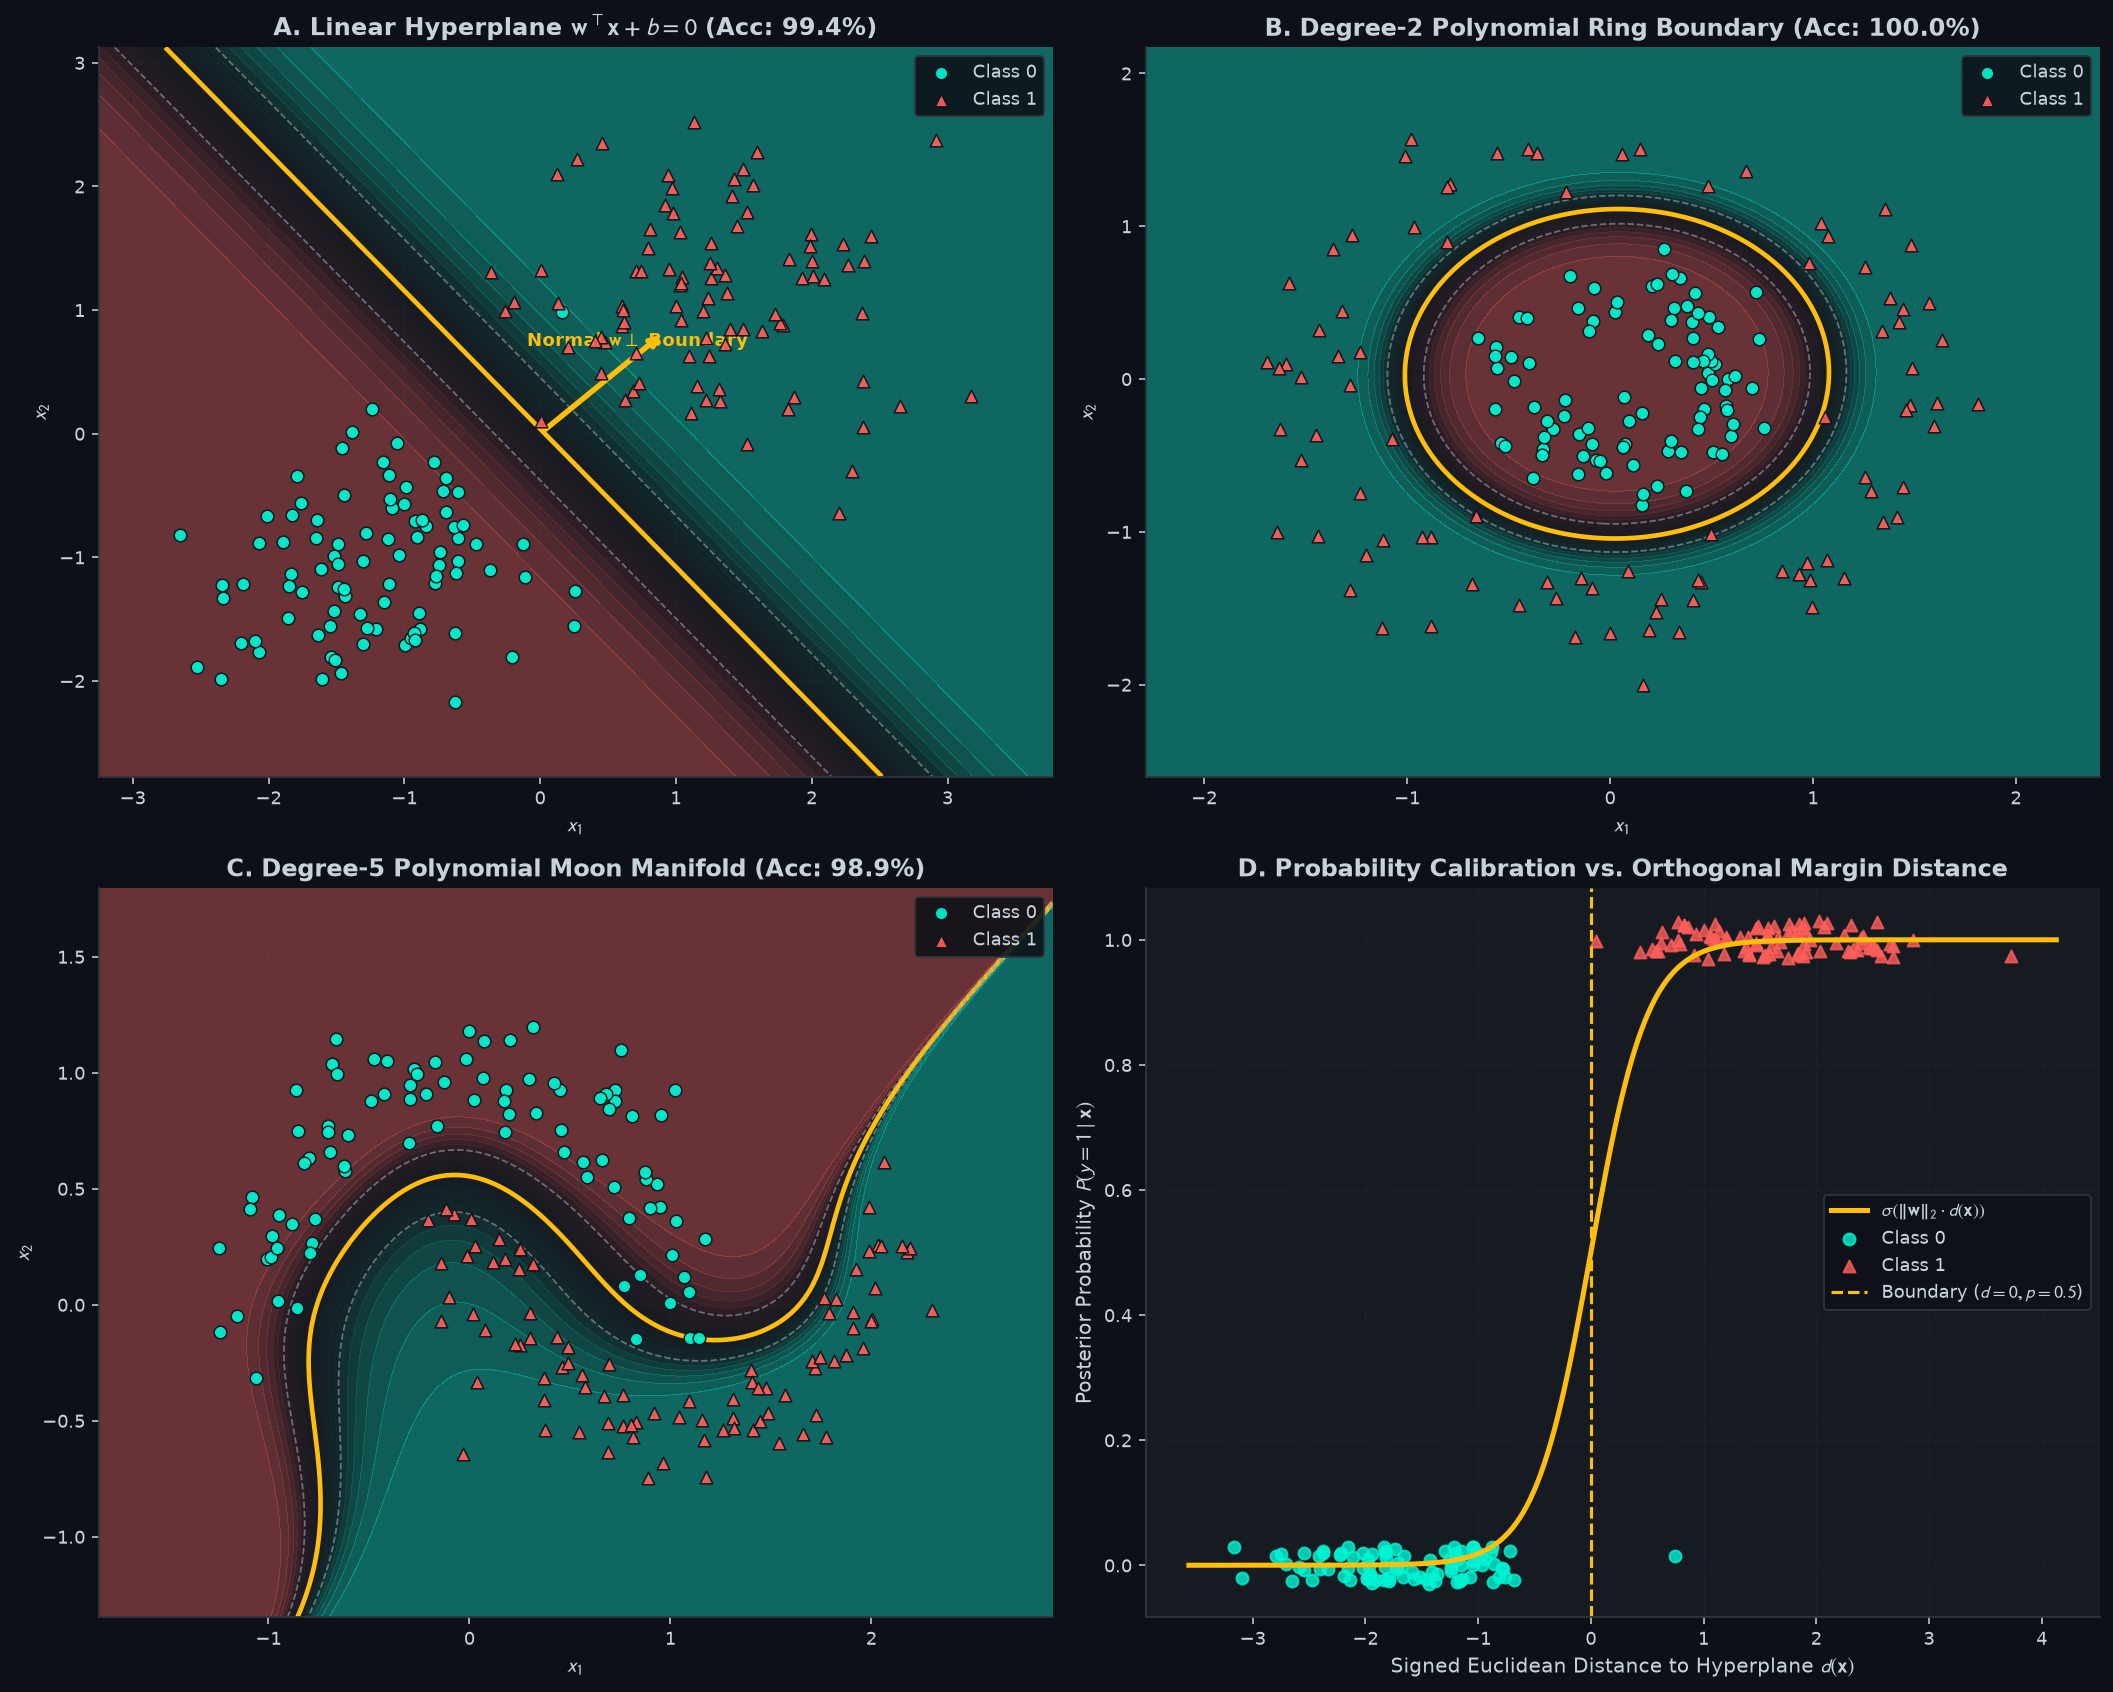

In [3]:
rng = np.random.default_rng(42)
m_half = 90

# Dataset 1: Linear Clusters
X_lin = np.vstack([rng.normal([-1.2, -1.0], 0.68, (m_half, 2)), rng.normal([1.2, 1.1], 0.68, (m_half, 2))])
y_lin = np.concatenate([np.zeros(m_half), np.ones(m_half)])

# Dataset 2: Concentric Rings
ang0, r0 = rng.uniform(0, 2*np.pi, m_half), rng.normal(0.55, 0.14, m_half)
ang1, r1 = rng.uniform(0, 2*np.pi, m_half), rng.normal(1.55, 0.18, m_half)
X_cir = np.vstack([np.column_stack([r0*np.cos(ang0), r0*np.sin(ang0)]), np.column_stack([r1*np.cos(ang1), r1*np.sin(ang1)])])
y_cir = np.concatenate([np.zeros(m_half), np.ones(m_half)])

# Dataset 3: Moons
t_m0 = np.linspace(0, np.pi, m_half)
X_m0 = np.column_stack([np.cos(t_m0), np.sin(t_m0)]) + rng.normal(0, 0.14, (m_half, 2))
t_m1 = np.linspace(0, np.pi, m_half)
X_m1 = np.column_stack([1.0 - np.cos(t_m1), 0.45 - np.sin(t_m1)]) + rng.normal(0, 0.14, (m_half, 2))
X_moon = np.vstack([X_m0, X_m1])
y_moon = np.concatenate([np.zeros(m_half), np.ones(m_half)])

# Train models
clf_lin = LogisticRegressionGD(learning_rate=0.25, epochs=600).fit(X_lin, y_lin)

poly_deg2 = PolynomialFeaturesScratch(degree=2, include_bias=False)
scaler_cir = StandardScalerScratch()
X_cir_poly = scaler_cir.fit_transform(poly_deg2.fit_transform(X_cir))
clf_cir = LogisticRegressionGD(learning_rate=0.35, epochs=800).fit(X_cir_poly, y_cir)

poly_deg5 = PolynomialFeaturesScratch(degree=5, include_bias=False)
scaler_moon = StandardScalerScratch()
X_moon_poly = scaler_moon.fit_transform(poly_deg5.fit_transform(X_moon))
clf_moon = LogisticRegressionGD(learning_rate=0.4, epochs=1200, penalty="l2", reg_lambda=0.05).fit(X_moon_poly, y_moon)

fig, axes = plt.subplots(2, 2, figsize=(15.2, 12.2))

# Panel A: Linear Boundary + Normal Vector w
plot_decision_boundary(
    predict_fn=lambda g: clf_lin.predict_proba(g),
    X=X_lin,
    y=y_lin,
    ax=axes[0, 0],
    title=f"A. Linear Hyperplane $\\mathbf{{w}}^\\top\\mathbf{{x}}+b=0$ (Acc: {clf_lin.accuracy(X_lin, y_lin)*100:.1f}%)",
)
w_vec = clf_lin.w.ravel()
w_norm = float(np.linalg.norm(w_vec))
x0 = -clf_lin.bias * w_vec / (w_norm ** 2)
unit_w = w_vec / w_norm
axes[0, 0].annotate(
    "",
    xy=(x0[0] + 1.2 * unit_w[0], x0[1] + 1.2 * unit_w[1]),
    xytext=(x0[0], x0[1]),
    arrowprops=dict(arrowstyle="->", color=AMBER, lw=2.8),
)
axes[0, 0].text(
    x0[0] + 0.65 * unit_w[0] - 0.6,
    x0[1] + 0.65 * unit_w[1] + 0.25,
    r"Normal $\mathbf{w} \perp$ Boundary",
    color=AMBER,
    fontweight="bold",
    fontsize=9.5,
)

# Panel B: Degree-2 Polynomial Concentric Rings
plot_decision_boundary(
    predict_fn=lambda g: clf_cir.predict_proba(scaler_cir.transform(poly_deg2.transform(g))),
    X=X_cir,
    y=y_cir,
    ax=axes[0, 1],
    title=f"B. Degree-2 Polynomial Ring Boundary (Acc: {clf_cir.accuracy(X_cir_poly, y_cir)*100:.1f}%)",
)

# Panel C: Degree-5 Polynomial Moon Manifold
plot_decision_boundary(
    predict_fn=lambda g: clf_moon.predict_proba(scaler_moon.transform(poly_deg5.transform(g))),
    X=X_moon,
    y=y_moon,
    ax=axes[1, 0],
    title=f"C. Degree-5 Polynomial Moon Manifold (Acc: {clf_moon.accuracy(X_moon_poly, y_moon)*100:.1f}%)",
)

# Panel D: Signed Distance Calibration
ax4 = axes[1, 1]
signed_dist = (X_lin @ clf_lin.w + clf_lin.bias).ravel() / w_norm
d_curve = np.linspace(signed_dist.min() - 0.4, signed_dist.max() + 0.4, 250)
p_curve = 1.0 / (1.0 + np.exp(-w_norm * d_curve))

ax4.plot(d_curve, p_curve, color=AMBER, linewidth=2.6, label=r"$\sigma(\|\mathbf{w}\|_2 \cdot d(\mathbf{x}))$")
m0, m1 = y_lin == 0, y_lin == 1
ax4.scatter(signed_dist[m0], y_lin[m0] + rng.uniform(-0.03, 0.03, np.sum(m0)), color=CYAN, s=38, alpha=0.8, label="Class 0")
ax4.scatter(signed_dist[m1], y_lin[m1] + rng.uniform(-0.03, 0.03, np.sum(m1)), color=CORAL, s=38, marker="^", alpha=0.8, label="Class 1")
ax4.axvline(0.0, color=AMBER, linestyle="--", linewidth=1.6, label="Boundary ($d=0, p=0.5$)")
ax4.set_xlabel(r"Signed Euclidean Distance to Hyperplane $d(\mathbf{x})$")
ax4.set_ylabel(r"Posterior Probability $P(y=1 \mid \mathbf{x})$")
ax4.set_title("D. Probability Calibration vs. Orthogonal Margin Distance")
ax4.legend(loc="center right")

fig.tight_layout()
save_fig(fig, REPO_DIR / "assets" / "07_logistic_gd_decision_boundaries.png")
plt.show()